<a href="https://colab.research.google.com/github/angiemarian123456-art/METODOS-NUMERICOS-1/blob/main/METODO_DE_NEVILLE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Resultados de la interpolación de Neville:

x_i    | Q_i,0       Q_i,1       Q_i,2       Q_i,3       Q_i,4      
--------------------------------------------------------------------
1.0    | 0.7651977   0.0000000   0.0000000   0.0000000   0.0000000
1.3    | 0.6200860   0.5233449   0.0000000   0.0000000   0.0000000
1.6    | 0.4554022   0.5102968   0.5124715   0.0000000   0.0000000
1.9    | 0.2818186   0.5132634   0.5112857   0.5118127   0.0000000
2.2    | 0.1103623   0.5104270   0.5137361   0.5118302   0.5118200

--- Verificación ---
Aproximación lineal Q_1,1(1.5) = 0.5233449
Aproximación lineal Q_2,1(1.5) = 0.5102968
Aproximación cuadrática Q_2,2(1.5) = 0.5124715

SOLUCIÓN FINAL: P(1.5) = Q_4,4 = 0.5118200


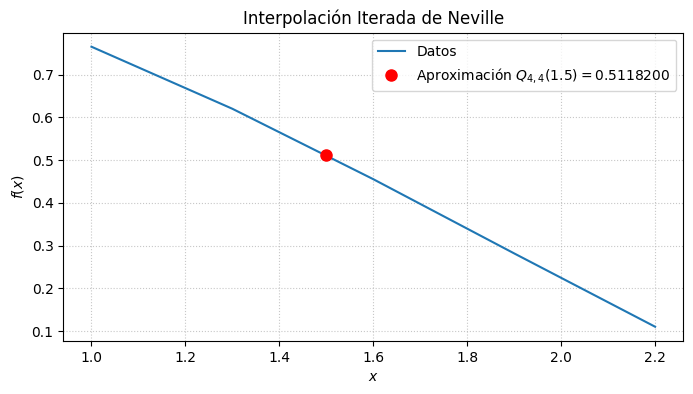

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def metodo_neville(nodos_x, valores_y, punto_x):
    n = len(nodos_x) - 1

    # Matriz (n+1) x (n+1)
    Q = np.zeros((n + 1, n + 1), dtype=float)

    # Primera columna Q_{i,0} = f(x_i)
    Q[:, 0] = valores_y

    # Polinomios
    for i in range(1, n + 1):
        for j in range(1, i + 1):
            numerador = ((punto_x - nodos_x[i - j]) * Q[i, j - 1]) - ((punto_x - nodos_x[i]) * Q[i - 1, j - 1])
            denominador = nodos_x[i] - nodos_x[i - j]
            Q[i, j] = numerador / denominador

    return Q[n, n], Q

def imprimir_tabla_3_6(nodos_x, Q):
    print(" Resultados de la interpolación de Neville:\n")
    print(f"{'x_i':<6} | {'Q_i,0':<11} {'Q_i,1':<11} {'Q_i,2':<11} {'Q_i,3':<11} {'Q_i,4':<11}")
    print("-" * 68)

    num_filas = Q.shape[0]
    for i in range(num_filas):
        valores_fila = [f"{Q[i, j]:.7f}" for j in range(Q.shape[1])]
        print(f"{nodos_x[i]:<6.1f} | " + "   ".join(valores_fila))

##### PRUEBA CON EL EJEMPLO 2 DEL BURDEN #####

# Datos
x_tabla = np.array([1.0, 1.3, 1.6, 1.9, 2.2])
fx_tabla = np.array([0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623])
x_objetivo = 1.5

# Ejecución
resultado_final, matriz_Q = metodo_neville(x_tabla, fx_tabla, x_objetivo)

# Tabla
imprimir_tabla_3_6(x_tabla, matriz_Q)
print("\n--- Verificación ---")
print(f"Aproximación lineal Q_1,1(1.5) = {matriz_Q[1, 1]:.7f}")
print(f"Aproximación lineal Q_2,1(1.5) = {matriz_Q[2, 1]:.7f}")
print(f"Aproximación cuadrática Q_2,2(1.5) = {matriz_Q[2, 2]:.7f}")

# Resultado
print("\n" + "=" * 52)
print(f"SOLUCIÓN FINAL: P({x_objetivo}) = Q_4,4 = {resultado_final:.7f}")
print("=" * 52)

### GRAFICA ###
plt.figure(figsize=(8, 4))
plt.plot(x_tabla, fx_tabla, label='Datos')
plt.plot(x_objetivo, resultado_final, 'ro', markersize=8, label=f'Aproximación $Q_{{4,4}}(1.5) = {resultado_final:.7f}$')
plt.title('Interpolación Iterada de Neville')
plt.xlabel('$x$')
plt.ylabel('$f(x)$')
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()
plt.show()